# 1 Importing Packages

How the *MESSAGE_CA* class works: the class will contain all the functions necessary to run the MESSAGEix Canada model. All that you need to run a model is to:

1. Create your scenario folder under `model/scenarios` with its own `config.toml` file

2. Declare the class reading that scenario, for example: `platform, msg, msg_folder = MESSAGE_CA(scenario_name='baseline')`

In [1]:
import os
import sys

from model.Model import model_MSG
from model.Plotter import plotter_MSG
from model.coders_linkage import CODERS_pull


# Autoreload modules when changes are applied to them
%load_ext autoreload 
%autoreload all

In [2]:
# Sys and OS Operations
os.chdir("../../")

# Scenario Creation and Set-up

Setting up the MESSAGEix scenario using the scenario configuration file and an input file for technology options in technology.yaml

In [3]:
# CODERS pulls and check-ups

msg_pull = CODERS_pull("key.txt")
generation_generic = msg_pull.create_generation_generic()
#msg_pull.generator_costs(generation_generic)
generators = msg_pull.calculate_closure_years(generation_generic)
cap_prov, cap_prov_dict = msg_pull.generation_capacity_provincial(generators, 2020, 2050)
hist_activity = msg_pull.historical_activity(generators, 2020, 2050)
cap_factors = msg_pull.get_capacity_factors(generators,2020,2050)

In [ ]:
#cap_prov
generators#.to_excel("Generators.xlsx", sheet_name="Gen_type_data")
hist_activity
#cap_factors

,node_loc,technology,year_act,mode,time,value,unit
0,Alberta,bio_istig,2020,M1,year,0.000000,GWa/a
1,Alberta,bio_istig,2021,M1,year,0.000000,GWa/a
2,Alberta,bio_istig,2022,M1,year,0.000000,GWa/a
3,Alberta,bio_istig,2023,M1,year,0.000000,GWa/a
4,Alberta,bio_istig,2024,M1,year,0.000000,GWa/a
...,...,...,...,...,...,...,...
4025,Saskatchewan,solar_pv_ppl,2046,M1,year,0.025201,GWa/a
4026,Saskatchewan,solar_pv_ppl,2047,M1,year,0.025201,GWa/a
4027,Saskatchewan,solar_pv_ppl,2048,M1,year,0.025201,GWa/a
4028,Saskatchewan,solar_pv_ppl,2049,M1,year,0.025201,GWa/a


In [3]:
# Set-up
msg = model_MSG(scenario_name='baseline')
platform, msg_scenario, msg_folder = msg.setup_scenario()


2024-11-18 14:35:16,697  INFO at.ac.iiasa.ixmp.Platform:165 - Welcome to the IX modeling platform!
2024-11-18 14:35:16,698  INFO at.ac.iiasa.ixmp.Platform:166 -  connected to database 'jdbc:hsqldb:file:/home/jgmonroe/.local/share/ixmp/localdb/default' (user: ixmp)...
Config file read successfully!
####################################################################################################
Config file 'model/scenarios/baseline/config.toml' passed format verification!
####################################################################################################


ValueError: The index set 'year' does not have an element '0'!

In [14]:
df = msg_scenario.var("EMISS")
df[(df["emission"] == "TCE") & (df['type_tec']== 'all')]

,node,emission,type_tec,year,lvl,mrg
14706,World,TCE,all,2020,6.278083e+08,0.0
14707,World,TCE,all,2025,6.522621e+08,0.0
14708,World,TCE,all,2030,6.681445e+08,0.0
14709,World,TCE,all,2035,7.224668e+08,0.0
14710,World,TCE,all,2040,7.742343e+08,0.0
...,...,...,...,...,...,...
232438,Yukon,TCE,all,2040,1.188269e+06,0.0
232439,Yukon,TCE,all,2045,1.272918e+06,0.0
232440,Yukon,TCE,all,2050,1.353276e+06,0.0
232441,Yukon,TCE,all,2055,1.432608e+06,0.0


In [ ]:
# Legacy Reporter
from message_ix_models.report.legacy.iamc_report_hackathon import report

report(mp=platform, scen=msg_scenario, out_dir="/home/jgmonroe/Documents/Energy_Models/message-ix/")

processing Table: Resource|Extraction
processing Table: Resource|Cumulative Extraction
processing Table: Primary Energy
processing Table: Primary Energy (substitution method)
processing Table: Final Energy
processing Table: Secondary Energy|Electricity
processing Table: Secondary Energy|Heat
processing Table: Secondary Energy
processing Table: Secondary Energy|Gases
processing Table: Secondary Energy|Solids
processing Table: Emissions|CO2
processing Table: Carbon Sequestration
processing Table: Emissions|BC
No unit conversion factor found to convert GWa/a to Mt BC/yr
'DataFrame' object has no attribute 'Region'
processing Table: Emissions|OC
No unit conversion factor found to convert GWa/a to Mt OC/yr
'DataFrame' object has no attribute 'Region'
processing Table: Emissions|CO
No unit conversion factor found to convert GWa/a to Mt CO/yr
'DataFrame' object has no attribute 'Region'
processing Table: Emissions|N2O
'DataFrame' object has no attribute 'Region'
processing Table: Emissions|CH

## Plotting and Reporting

In [5]:
msg_plt = plotter_MSG(msg_scenario)
nodes = msg_scenario.set('node')[2:]


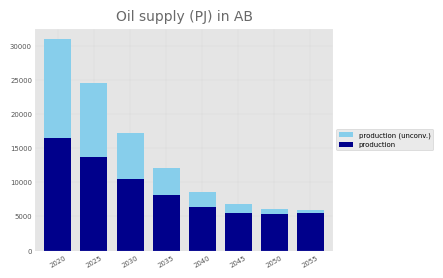

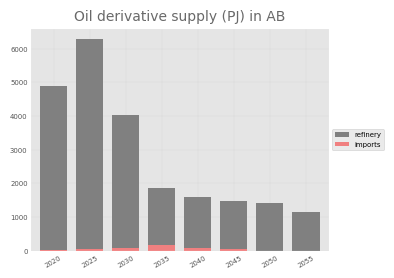

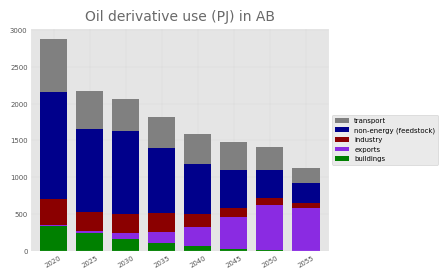

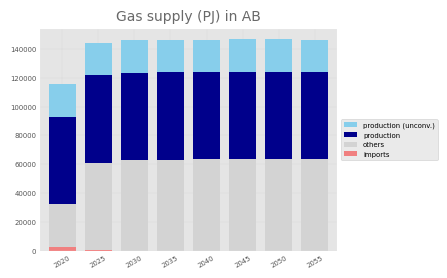

> WARNING: There is no solution data in the selected years and limits to be plotted for Gas utilization (PJ)!


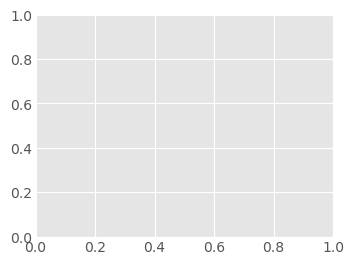

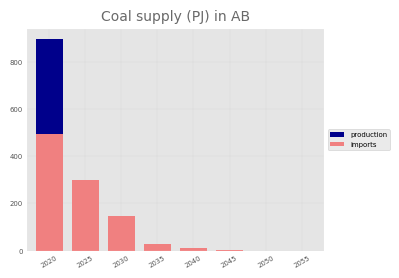

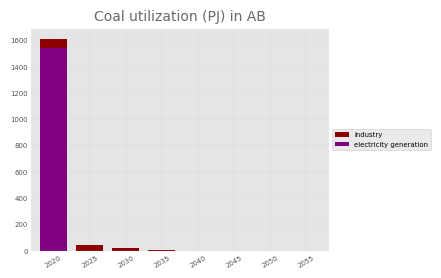

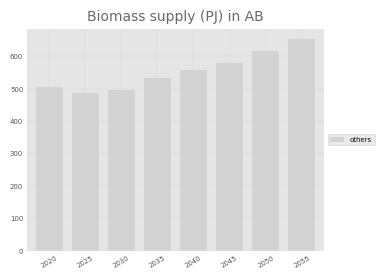

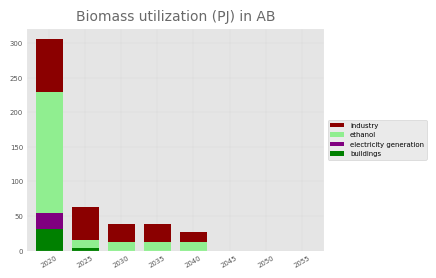

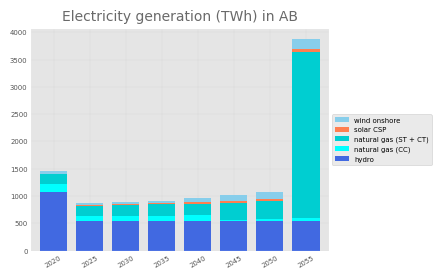

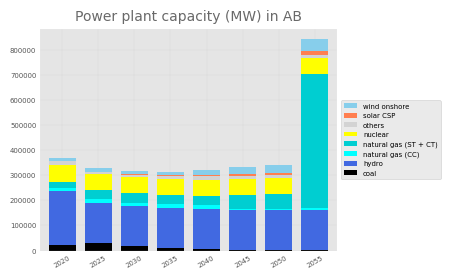

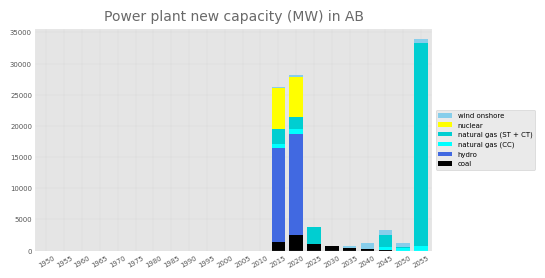

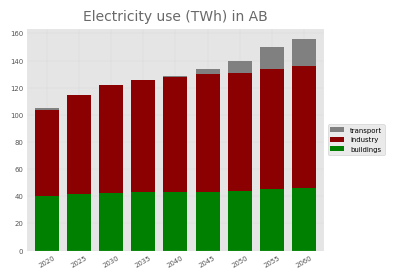

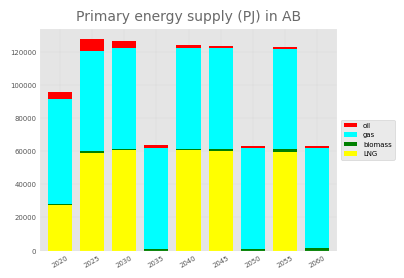

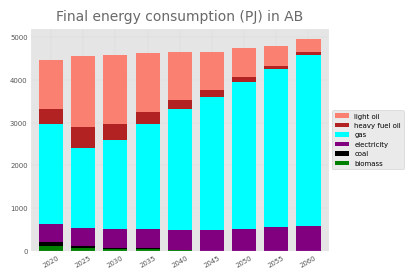

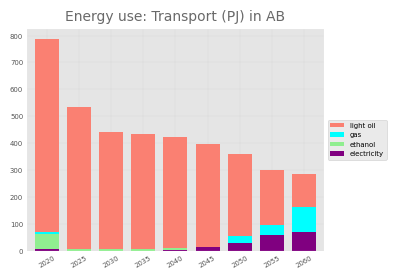

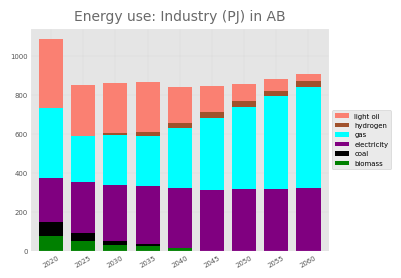

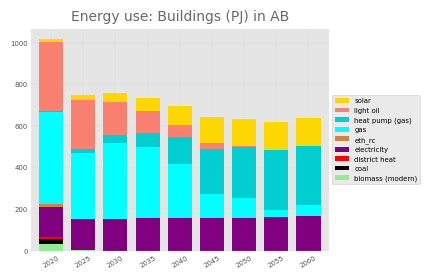

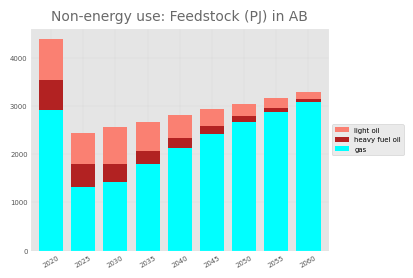

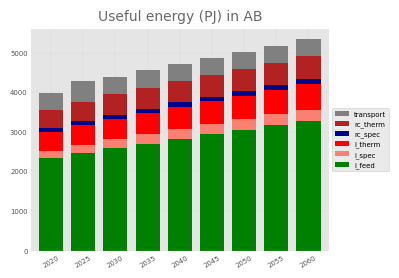

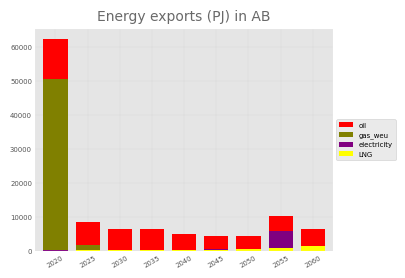

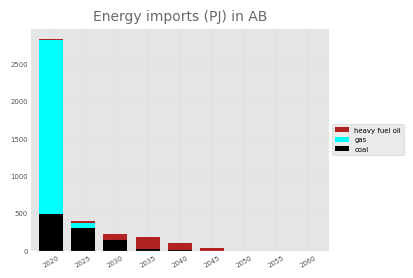

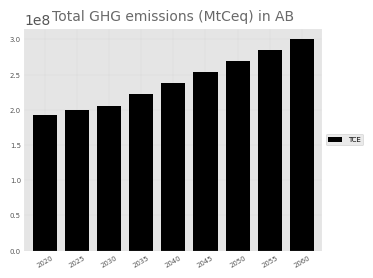

{'Electricity generation (TWh)':             hydro  natural gas (CC)  natural gas (ST + CT)  solar CSP  \
 2020  1071.037742        152.284575             186.287789   1.240826   
 2025   543.636236         85.627329             195.530030   3.741254   
 2030   543.636236         98.480080             198.723582   8.141256   
 2035   543.199784         99.083171             207.646218  14.774690   
 2040   542.848739        103.501243             215.786286  23.514818   
 2045   542.848739         22.532733             313.154728  35.525922   
 2050   541.334728         37.302333             324.869223  49.732029   
 2055   541.334728         61.728333            3029.676000  68.930184   
 
       wind onshore  
 2020     51.830191  
 2025     44.678287  
 2030     44.678287  
 2035     49.692041  
 2040     77.145631  
 2045     99.694178  
 2050    111.267510  
 2055    168.125783  ,
 'Power plant capacity (MW)':               coal          hydro  natural gas (CC)  natural gas (ST + 

In [12]:
# Plots

msg_plt.plotter(case="test",nodeloc=["Alberta"],path=os.getcwd()+'/output/tests',yr_min=2020, yr_max=2060)

In [ ]:
msg_plt.report_to_pyam(directory_path=os.getcwd()+'/output/tests', output_path=os.getcwd()+'/output/output_dataframes')